# WGAN vs WGAN-GP on the FULL CIFAR-10 Training Set
**Student:** Katravath Naveen  
**Roll No.:** 24CS3027 | **Assignment:** DL-078  
**Paper:** Gulrajani et al., *Improved Training of Wasserstein GANs* (2017)

## Aim
Implement and compare (1) WGAN with weight clipping and (2) WGAN-GP with gradient penalty on all 50,000 CIFAR-10 training images. Compare critic/generator training curves, generated image samples, and an approximate Inception-feature FID score.

## Important
- This notebook uses the **full 50,000-image CIFAR-10 training set**, not a 5,000-image subset.
- Main comparison: 3 epochs per method. WGAN-GP is computationally expensive; on a free Colab GPU, runtime may be long.
- FID is estimated using 500 real and 500 generated images, so it is approximate.
- Results in this notebook are placeholders only until you run it. Use only your own actual outputs in the report.


## Cell 1 — Enable GPU
In Colab, choose **Runtime → Change runtime type → T4 GPU** (if available). Then run the following cell.

In [1]:
import torch, torchvision, numpy as np, matplotlib.pyplot as plt, random, time, os, copy
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


## Cell 2 — Configuration
The full dataset is used below. Run in Google Colab with **Runtime → Change runtime type → T4 GPU** if available. Full-set WGAN-GP training takes substantially longer than subset training.

If Colab disconnects or runs out of time, reduce `EPOCHS` temporarily for a smoke test, but restore it to 3 for the final run. Do not report a reduced run as the full 3-epoch experiment.


In [2]:
SEED = 42
BATCH_SIZE = 64
EPOCHS = 3
Z_DIM = 100
N_CRITIC = 5
LAMBDA_GP = 10.0
IMAGE_SIZE = 32
NUM_WORKERS = 2
FID_IMAGES = 500
OUTPUT_DIR = "wgan_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)
print("Seed:", SEED, "| Epochs per main method:", EPOCHS)


Using: cuda
Seed: 42 | Epochs per main method: 3


In [11]:
# Configuration for CIFAR-10 DataLoader

import torch

BATCH_SIZE = 64
NUM_WORKERS = 2

print("BATCH_SIZE =", BATCH_SIZE)
print("NUM_WORKERS =", NUM_WORKERS)
print("GPU available =", torch.cuda.is_available())

BATCH_SIZE = 64
NUM_WORKERS = 2
GPU available = True


## Cell 3 — Load the full CIFAR-10 training set
CIFAR-10 has 50,000 training images and 10,000 test images. This experiment trains on all 50,000 training images. Images are scaled to `[-1, 1]` to match the Generator's `Tanh` output.


In [12]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=True,
    persistent_workers=(NUM_WORKERS > 0)
)

print("Full CIFAR-10 training images:", len(train_dataset))
print("Images per epoch:", len(train_loader) * BATCH_SIZE)
assert len(train_dataset) == 50000, "Expected all 50,000 CIFAR-10 training images."


Full CIFAR-10 training images: 50000
Images per epoch: 49984


In [14]:
import torch
import torchvision
import matplotlib.pyplot as plt

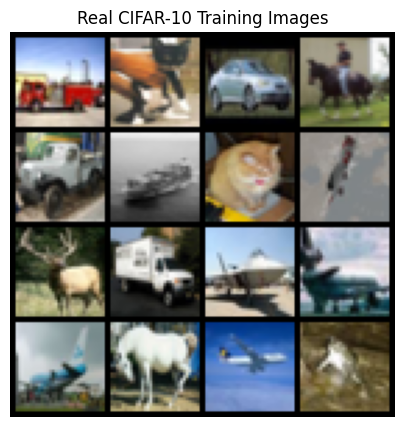

In [15]:
def show_real_images():
    images, labels = next(iter(train_loader))

    images = (images[:16] * 0.5 + 0.5).clamp(0, 1)
    grid = torchvision.utils.make_grid(images, nrow=4)

    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title("Real CIFAR-10 Training Images")
    plt.axis("off")
    plt.show()

show_real_images()

In [17]:
import torch

Z_DIM = 100
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = DEVICE

print("Z_DIM:", Z_DIM)
print("Device:", device)

Z_DIM: 100
Device: cuda


## Cell 4 — Define Generator and Critic
The generator maps random noise (`z`) to a 32×32 RGB image. The critic returns one score per image; unlike a normal GAN discriminator, it does not output a sigmoid probability.

In [18]:
import torch.nn as nn
import torch.nn.functional as F

class Generator(nn.Module):
    def __init__(self, z_dim=100, channels=3, base=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, base * 8, 4, 1, 0, bias=False), # 4x4
            nn.BatchNorm2d(base * 8), nn.ReLU(True),
            nn.ConvTranspose2d(base * 8, base * 4, 4, 2, 1, bias=False), # 8x8
            nn.BatchNorm2d(base * 4), nn.ReLU(True),
            nn.ConvTranspose2d(base * 4, base * 2, 4, 2, 1, bias=False), # 16x16
            nn.BatchNorm2d(base * 2), nn.ReLU(True),
            nn.ConvTranspose2d(base * 2, channels, 4, 2, 1, bias=False), # 32x32
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)

class Critic(nn.Module):
    def __init__(self, channels=3, base=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(channels, base, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True), # 16x16
            nn.Conv2d(base, base * 2, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True), # 8x8
            nn.Conv2d(base * 2, base * 4, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True), # 4x4
            nn.Conv2d(base * 4, base * 8, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True), # 2x2
            nn.Flatten(),
            nn.Linear(base * 8 * 2 * 2, 1)
        )

    def forward(self, x):
        return self.net(x).view(-1)

g = Generator(Z_DIM).to(device)
c = Critic().to(device)
print("Generator parameters:", sum(p.numel() for p in g.parameters()))
print("Critic parameters:", sum(p.numel() for p in c.parameters()))

Generator parameters: 3448576
Critic parameters: 2758593


## Cell 5 — Gradient Penalty
WGAN-GP samples interpolated images between real and generated images, computes the critic's gradient with respect to those images, and penalises gradient norms that differ from 1.

In [19]:
def gradient_penalty(critic, real, fake):
    batch_size = real.size(0)
    alpha = torch.rand(batch_size, 1, 1, 1, device=real.device)
    interpolated = alpha * real + (1 - alpha) * fake
    interpolated.requires_grad_(True)

    scores = critic(interpolated)
    gradients = torch.autograd.grad(
        outputs=scores,
        inputs=interpolated,
        grad_outputs=torch.ones_like(scores),
        create_graph=True,
        retain_graph=True,
        only_inputs=True
    )[0]

    gradients = gradients.view(batch_size, -1)
    grad_norm = gradients.norm(2, dim=1)
    gp = ((grad_norm - 1) ** 2).mean()
    return gp

## Cell 6 — Training function for both methods
- **WGAN clipping:** RMSprop optimizer and clip each critic parameter to `[-0.01, 0.01]`.
- **WGAN-GP:** Adam optimizer and add `lambda × gradient_penalty` to critic loss.
- The critic is updated several times per generator update.

In [21]:
# Training configuration
EPOCHS = 3
LAMBDA_GP = 10
N_CRITIC = 5
Z_DIM = 100

print("EPOCHS:", EPOCHS)
print("LAMBDA_GP:", LAMBDA_GP)
print("N_CRITIC:", N_CRITIC)
print("Z_DIM:", Z_DIM)

EPOCHS: 3
LAMBDA_GP: 10
N_CRITIC: 5
Z_DIM: 100


In [22]:
def train_gan(method, epochs=EPOCHS, lambda_gp=LAMBDA_GP):
    assert method in ("clipping", "gp")
    generator = Generator(Z_DIM).to(device)
    critic = Critic().to(device)

    if method == "clipping":
        opt_g = torch.optim.RMSprop(generator.parameters(), lr=5e-5)
        opt_c = torch.optim.RMSprop(critic.parameters(), lr=5e-5)
    else:
        opt_g = torch.optim.Adam(generator.parameters(), lr=1e-4, betas=(0.0, 0.9))
        opt_c = torch.optim.Adam(critic.parameters(), lr=1e-4, betas=(0.0, 0.9))

    history = {"critic_loss": [], "generator_loss": [], "wasserstein_estimate": []}
    fixed_noise = torch.randn(16, Z_DIM, 1, 1, device=device)
    start = time.time()

    for epoch in range(epochs):
        c_losses, g_losses, w_estimates = [], [], []
        generator.train()
        critic.train()

        for batch_idx, (real, _) in enumerate(train_loader):
            real = real.to(device, non_blocking=True)
            batch_size = real.size(0)

            # Update critic
            for _ in range(N_CRITIC):
                z = torch.randn(batch_size, Z_DIM, 1, 1, device=device)
                fake = generator(z).detach()
                real_score = critic(real)
                fake_score = critic(fake)
                wasserstein_est = real_score.mean() - fake_score.mean()

                if method == "clipping":
                    loss_c = fake_score.mean() - real_score.mean()
                else:
                    gp = gradient_penalty(critic, real, fake)
                    loss_c = fake_score.mean() - real_score.mean() + lambda_gp * gp

                opt_c.zero_grad(set_to_none=True)
                loss_c.backward()
                opt_c.step()

                if method == "clipping":
                    for p in critic.parameters():
                        p.data.clamp_(-0.01, 0.01)

            # Update generator
            z = torch.randn(batch_size, Z_DIM, 1, 1, device=device)
            fake = generator(z)
            loss_g = -critic(fake).mean()
            opt_g.zero_grad(set_to_none=True)
            loss_g.backward()
            opt_g.step()

            c_losses.append(float(loss_c.detach().cpu()))
            g_losses.append(float(loss_g.detach().cpu()))
            w_estimates.append(float(wasserstein_est.detach().cpu()))

        history["critic_loss"].append(float(np.mean(c_losses)))
        history["generator_loss"].append(float(np.mean(g_losses)))
        history["wasserstein_estimate"].append(float(np.mean(w_estimates)))

        generator.eval()
        with torch.no_grad():
            samples = generator(fixed_noise).cpu()
        grid = torchvision.utils.make_grid((samples[:16] * 0.5 + 0.5).clamp(0, 1), nrow=4)
        plt.figure(figsize=(4, 4))
        plt.imshow(grid.permute(1, 2, 0))
        plt.title(f"{method.upper()} — epoch {epoch+1}/{epochs}")
        plt.axis("off")
        plt.show()

        print(f"{method} | Epoch {epoch+1}/{epochs} | "
              f"Critic loss: {history['critic_loss'][-1]:.4f} | "
              f"Generator loss: {history['generator_loss'][-1]:.4f} | "
              f"Elapsed: {(time.time()-start)/60:.1f} min")

    return generator, critic, history

## Cell 7 — Train WGAN with weight clipping
This may take several minutes. Let the cell finish before running the next cell.

In [24]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torchvision

print("Required libraries imported successfully!")

Required libraries imported successfully!


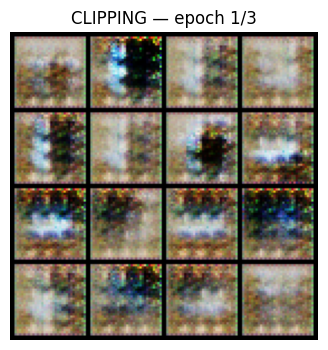

clipping | Epoch 1/3 | Critic loss: -59.2270 | Generator loss: 12.3177 | Elapsed: 2.2 min


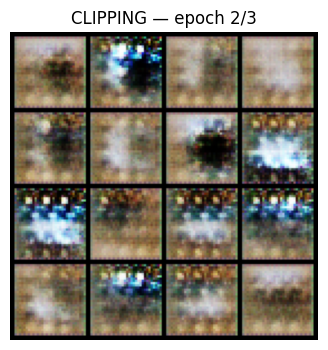

clipping | Epoch 2/3 | Critic loss: -28.6005 | Generator loss: 18.7114 | Elapsed: 4.4 min


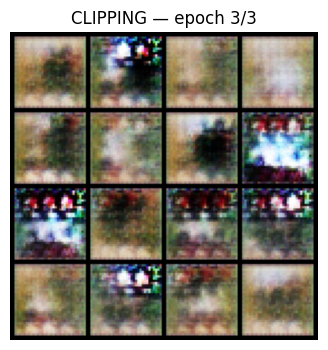

clipping | Epoch 3/3 | Critic loss: -22.8178 | Generator loss: 16.5960 | Elapsed: 6.5 min


In [25]:
G_clip, C_clip, hist_clip = train_gan("clipping")

## Cell 8 — Train WGAN-GP
This method is usually slower because it calculates second-order gradient information for the penalty.

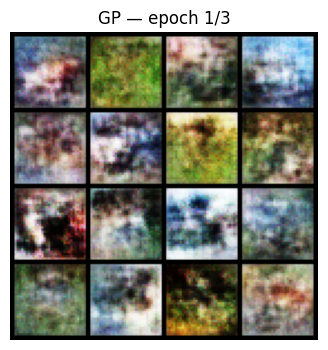

gp | Epoch 1/3 | Critic loss: -9.7312 | Generator loss: -6.4147 | Elapsed: 3.6 min


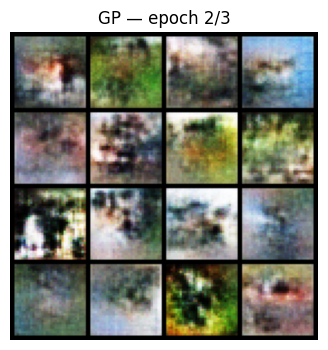

gp | Epoch 2/3 | Critic loss: -4.7788 | Generator loss: -17.1534 | Elapsed: 7.2 min


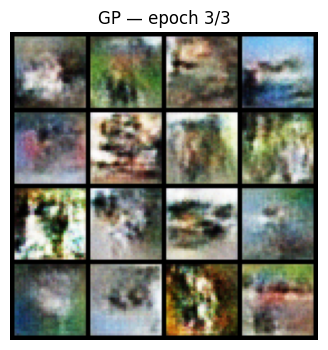

gp | Epoch 3/3 | Critic loss: -4.0736 | Generator loss: -13.3430 | Elapsed: 10.8 min


In [26]:
G_gp, C_gp, hist_gp = train_gan("gp")

## Cell 9 — Plot critic loss and generator loss
The critic loss is a training signal, not a direct measure of image quality. Look at loss curves together with generated images and FID.

In [28]:
import os
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = "wgan_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries imported and output folder ready!")

Libraries imported and output folder ready!


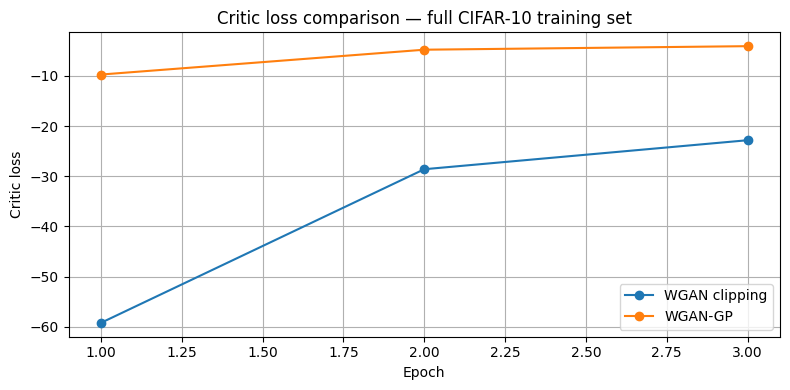

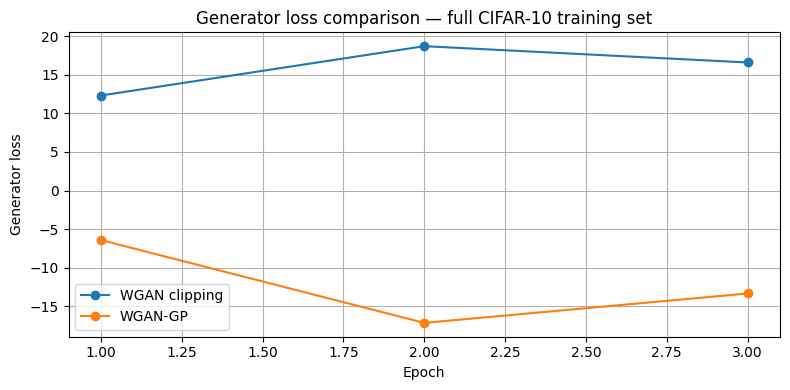

In [29]:
epochs_axis = np.arange(1, EPOCHS + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs_axis, hist_clip["critic_loss"], marker="o", label="WGAN clipping")
plt.plot(epochs_axis, hist_gp["critic_loss"], marker="o", label="WGAN-GP")
plt.xlabel("Epoch")
plt.ylabel("Critic loss")
plt.title("Critic loss comparison — full CIFAR-10 training set")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "critic_loss_comparison.png"), dpi=160)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs_axis, hist_clip["generator_loss"], marker="o", label="WGAN clipping")
plt.plot(epochs_axis, hist_gp["generator_loss"], marker="o", label="WGAN-GP")
plt.xlabel("Epoch")
plt.ylabel("Generator loss")
plt.title("Generator loss comparison — full CIFAR-10 training set")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "generator_loss_comparison.png"), dpi=160)
plt.show()


## Optional Ablation — Effect of the Gradient-Penalty Coefficient
The main comparison uses lambda = 10. This optional ablation trains WGAN-GP with lambda = 5 for one epoch on the full 50,000-image training set. It adds substantial runtime. Run it after the two main models finish; if runtime is limited, skip it and clearly state that the ablation was not run.


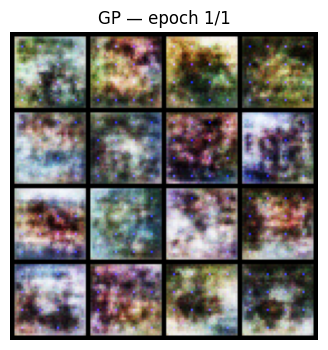

gp | Epoch 1/1 | Critic loss: -14.2021 | Generator loss: 3.5844 | Elapsed: 3.6 min
Ablation complete: lambda_GP=5, one epoch.


In [30]:
# Optional ablation. Set RUN_ABLATION = False if runtime is limited.
RUN_ABLATION = True
ABLATION_EPOCHS = 1

if RUN_ABLATION:
    G_gp_lam5, C_gp_lam5, hist_gp_lam5 = train_gan('gp', epochs=ABLATION_EPOCHS, lambda_gp=5.0)
    print("Ablation complete: lambda_GP=5, one epoch.")
else:
    G_gp_lam5, C_gp_lam5, hist_gp_lam5 = None, None, None
    print("Ablation skipped by configuration.")


## Cell 10 — Compare generated samples side by side

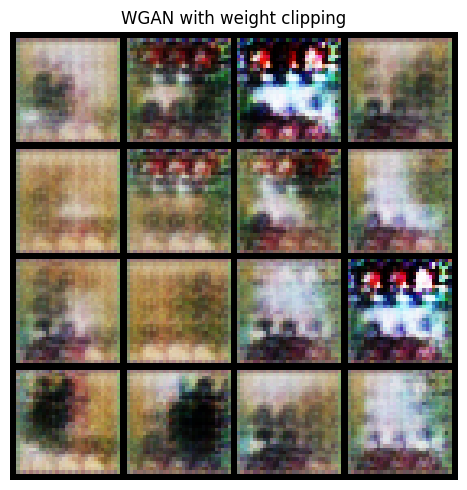

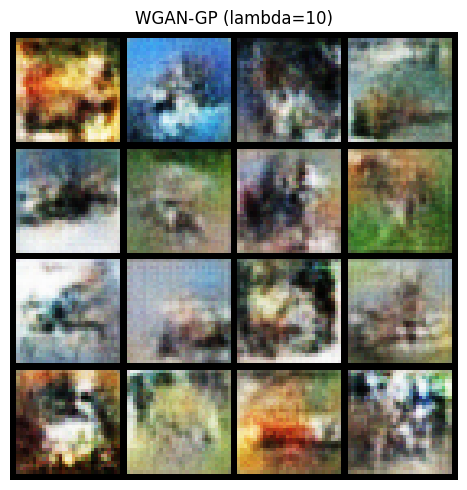

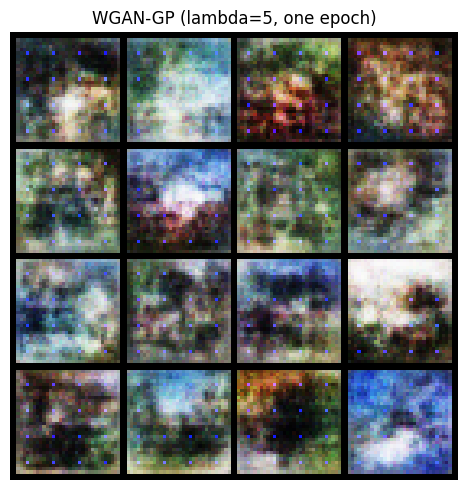

In [31]:
def make_sample_grid(generator, title, filename, n=16):
    generator.eval()
    with torch.no_grad():
        z = torch.randn(n, Z_DIM, 1, 1, device=device)
        imgs = generator(z).cpu()
    grid = torchvision.utils.make_grid((imgs * 0.5 + 0.5).clamp(0, 1), nrow=4)
    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=160)
    plt.show()

make_sample_grid(G_clip, "WGAN with weight clipping", "wgan_clipping_samples.png")
make_sample_grid(G_gp, "WGAN-GP (lambda=10)", "wgan_gp_samples.png")
if RUN_ABLATION:
    make_sample_grid(G_gp_lam5, "WGAN-GP (lambda=5, one epoch)", "wgan_gp_lambda5_samples.png")


## Cell 11 — Approximate FID using pretrained Inception features
FID compares feature distributions of real and generated images; lower is generally better. This cell uses pretrained Inception-v3 features and a limited sample count to keep the experiment manageable. The score is approximate and can be noisy with few images. The first run downloads pretrained weights and needs internet access.

In [33]:
FID_IMAGES = 500

print("FID_IMAGES =", FID_IMAGES)

FID_IMAGES = 500


In [34]:
from torchvision.models import inception_v3, Inception_V3_Weights
from scipy.linalg import sqrtm

weights = Inception_V3_Weights.DEFAULT
inception = inception_v3(weights=weights)
inception.fc = nn.Identity()
inception.AuxLogits = None
inception.aux_logits = False
inception = inception.to(device).eval()

fid_transform = transforms.Compose([
    transforms.Resize((299, 299), antialias=True),
    transforms.Normalize(mean=(0.485, 0.456, 0.406),
                         std=(0.229, 0.224, 0.225))
])

@torch.no_grad()
def get_real_features(dataset, max_images=FID_IMAGES, batch_size=32):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    feats, count = [], 0
    for images, _ in loader:
        images = (images.to(device) * 0.5 + 0.5).clamp(0, 1)
        images = fid_transform(images)
        f = inception(images)
        feats.append(f.cpu().numpy())
        count += images.size(0)
        if count >= max_images:
            break
    return np.concatenate(feats, axis=0)[:max_images]

@torch.no_grad()
def get_fake_features(generator, n_images=FID_IMAGES, batch_size=32):
    generator.eval()
    feats, count = [], 0
    while count < n_images:
        n = min(batch_size, n_images - count)
        z = torch.randn(n, Z_DIM, 1, 1, device=device)
        images = (generator(z) * 0.5 + 0.5).clamp(0, 1)
        images = fid_transform(images)
        f = inception(images)
        feats.append(f.cpu().numpy())
        count += n
    return np.concatenate(feats, axis=0)[:n_images]

def calculate_fid(real_features, fake_features):
    mu1, mu2 = real_features.mean(axis=0), fake_features.mean(axis=0)
    cov1, cov2 = np.cov(real_features, rowvar=False), np.cov(fake_features, rowvar=False)
    covmean = sqrtm(cov1 @ cov2)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    fid = np.sum((mu1 - mu2) ** 2) + np.trace(cov1 + cov2 - 2 * covmean)
    return float(fid)

# Use CIFAR-10 test images as the real evaluation reference
test_full = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
FID_N = 500
real_features = get_real_features(test_full, max_images=FID_N)
fake_clip_features = get_fake_features(G_clip, n_images=FID_N)
fake_gp_features = get_fake_features(G_gp, n_images=FID_N)

fid_clip = calculate_fid(real_features, fake_clip_features)
fid_gp = calculate_fid(real_features, fake_gp_features)

print(f"Approximate FID — WGAN clipping: {fid_clip:.2f}")
print(f"Approximate FID — WGAN-GP:      {fid_gp:.2f}")

Approximate FID — WGAN clipping: 222.05
Approximate FID — WGAN-GP:      197.23


## Cell 12 — Results table
Use the values printed by your own run. Do not copy made-up numbers into the report.

In [35]:
# CELL 12: Final Results Table and Save CSV

import pandas as pd
from pathlib import Path

print("Checking training results...")

# Check whether the training histories exist
if "hist_clip" not in globals() or "hist_gp" not in globals():
    print("Training histories are not available.")
    print("Please run the WGAN and WGAN-GP training cells first.")

else:
    # Extract loss histories
    clip_critic = hist_clip.get("critic_loss", [])
    clip_generator = hist_clip.get("generator_loss", [])
    gp_critic = hist_gp.get("critic_loss", [])
    gp_generator = hist_gp.get("generator_loss", [])

    if not all([clip_critic, clip_generator, gp_critic, gp_generator]):
        print("Loss history is empty. Check whether both training runs completed.")

    elif "fid_clip" not in globals() or "fid_gp" not in globals():
        print("Training losses are available, but FID scores are missing.")
        print("Run the FID evaluation cell before creating the final table.")

    else:
        results = {
            "Method": [
                "WGAN with weight clipping",
                "WGAN-GP"
            ],
            "Dataset": [
                "CIFAR-10 training set (50,000 images)",
                "CIFAR-10 training set (50,000 images)"
            ],
            "Epochs completed": [
                len(clip_critic),
                len(gp_critic)
            ],
            "Final critic loss": [
                clip_critic[-1],
                gp_critic[-1]
            ],
            "Final generator loss": [
                clip_generator[-1],
                gp_generator[-1]
            ],
            "Approximate FID": [
                fid_clip,
                fid_gp
            ]
        }

        results_df = pd.DataFrame(results)
        display(results_df)

        output_dir = Path("wgan_outputs")
        output_dir.mkdir(parents=True, exist_ok=True)

        results_df.to_csv(
            output_dir / "wgan_vs_wgan_gp_results.csv",
            index=False
        )

        print("Results table and CSV saved successfully.")

Checking training results...


,Method,Dataset,Epochs completed,Final critic loss,Final generator loss,Approximate FID
0,WGAN with weight clipping,"CIFAR-10 training set (50,000 images)",3,-22.817833,16.596018,222.050471
1,WGAN-GP,"CIFAR-10 training set (50,000 images)",3,-4.073642,-13.343050,197.230306


Results table and CSV saved successfully.


## Cell 13 — Save results
Downloads a CSV containing the final comparison metrics. You can also save this notebook using **File → Download → Download .ipynb**.

In [36]:
results_df.to_csv(os.path.join(OUTPUT_DIR, "wgan_vs_wgan_gp_results.csv"), index=False)
print("Saved:", os.path.join(OUTPUT_DIR, "wgan_vs_wgan_gp_results.csv"))

# Save the epoch-wise training histories too.
history_df = pd.DataFrame({
    "epoch": list(range(1, EPOCHS + 1)),
    "wgan_clipping_critic_loss": hist_clip["critic_loss"],
    "wgan_clipping_generator_loss": hist_clip["generator_loss"],
    "wgan_gp_critic_loss": hist_gp["critic_loss"],
    "wgan_gp_generator_loss": hist_gp["generator_loss"]
})
history_df.to_csv(os.path.join(OUTPUT_DIR, "epoch_loss_history.csv"), index=False)
print("Saved:", os.path.join(OUTPUT_DIR, "epoch_loss_history.csv"))

try:
    from google.colab import files
    files.download(os.path.join(OUTPUT_DIR, "wgan_vs_wgan_gp_results.csv"))
except Exception:
    print("Not running in Google Colab; results are saved in the output folder.")


Saved: wgan_outputs/wgan_vs_wgan_gp_results.csv
Saved: wgan_outputs/epoch_loss_history.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Report template

### Abstract
This project compares Wasserstein GAN training with weight clipping and Wasserstein GAN with Gradient Penalty (WGAN-GP) on CIFAR-10. Both models generate 32×32 RGB images. Their training curves, generated samples, and approximate Inception-feature FID scores are compared.

### Methodology
1. Normalize CIFAR-10 images to [-1, 1].
2. Build a generator and a critic.
3. Train WGAN using RMSprop and critic weight clipping.
4. Train WGAN-GP using Adam and a gradient penalty with λ = 10.
5. Compare loss curves, generated samples, and approximate FID.

### Results
Insert your actual plots, sample grids, and the table produced in Cell 12. Explain whether the lower FID method also looked better visually. Mention the number of images and epochs used.

### Conclusion
State the result observed in your run. WGAN-GP is designed to improve critic regularisation and training stability without weight clipping, but a short run or small sample count may not show a reliable FID improvement.

### Limitations
The experiment uses a subset of CIFAR-10 and relatively few epochs. FID is approximate because only 500 real and 500 generated images are used. Longer training and more evaluation images are needed for stronger conclusions.

### Reference
Gulrajani, I., Ahmed, F., Arjovsky, M., Dumoulin, V., & Courville, A. (2017). *Improved Training of Wasserstein GANs*. NeurIPS. https://arxiv.org/abs/1704.00028